In [1]:
#MLP with keras
import numpy as np
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

x=np.random.randn(1000, 2).astype("float32")

y=((x[:, 0]+x[:, 1])>0).astype("float32")

model=tf.keras.Sequential([tf.keras.layers.Input(shape=(2,)),
                           tf.keras.layers.Dense(8, activation="relu"),
                           tf.keras.layers.Dense(4, activation="relu"),
                           tf.keras.layers.Dense(1, activation="sigmoid")
                           ])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65 (260.00 B)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 0 (0.00 B)

Metrics

In [2]:
import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

y_actual = np.array([50, 60, 70, 80])
y_pred = np.array([45, 65, 68, 75])

mae=mean_absolute_error(y_actual, y_pred)
mse=mean_squared_error(y_actual, y_pred)
rmse=np.sqrt(mse)

print(rmse)

4.444097208657794


In [3]:
import numpy as np
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, confusion_matrix)
y_actual=np.array([0]*50 + [1]*50)
y_pred=np.array([0]*40 + [1]*10 + [0]*40 + [1]*10)
accuracy = accuracy_score(y_actual, y_pred)
precision = precision_score(y_actual, y_pred)
print(accuracy)
print(precision)

0.5
0.5


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28)
(60000,)
(10000, 28, 28)


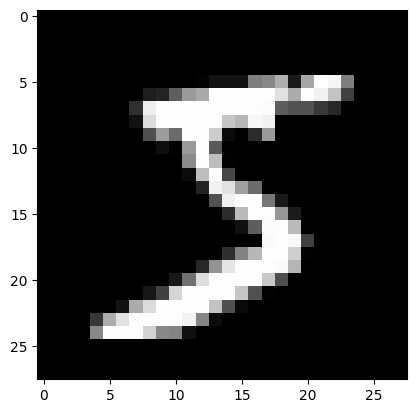

In [4]:
import numpy as np
from matplotlib import pyplot as plt
import tensorflow as tf

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)

plt.imshow(X_train[0], cmap="gray")

Learning PyTorch, MNIST using PyTorch

In [5]:
!pip install torch torchvision

In [6]:
import torch as pt
x=pt.tensor([10, 20, 30])
# print(type(x)) #<class 'torch.Tensor'>
# The important difference: PyTorch tensors support ""automatic gradient calculation"", which PyTorch uses during neural network training.

In [7]:
import torch
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

transform=transforms.ToTensor()
train_data=datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data=datasets.MNIST(
    root="./root",
    train=False,
    transform=transform,
    download=True
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 42.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 994kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.99MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.29MB/s]
100%|██████████| 9.91M/9.91M [00:00<00:00, 37.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.02MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.98MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.94MB/s]


In [8]:
print(len(train_data))

60000


In [9]:
image, label = train_data[0]
print(image.shape)
print(label)

torch.Size([1, 28, 28])
5


In [10]:
train_loader=DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)
test_loader=DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

for image, label in train_loader:
  print(image.shape)
  print(label)
  break

torch.Size([64, 1, 28, 28])
tensor([6, 0, 2, 5, 4, 1, 9, 6, 7, 7, 1, 2, 2, 0, 3, 6, 9, 3, 1, 8, 1, 1, 8, 3,
        0, 4, 2, 9, 3, 1, 2, 0, 6, 1, 1, 0, 4, 3, 5, 6, 0, 4, 4, 5, 2, 7, 6, 6,
        7, 2, 7, 7, 2, 2, 8, 6, 1, 1, 5, 8, 4, 5, 1, 6])


In [16]:
import torch
import torch.nn as nn
import torch.optim as optim

In [17]:
class MNISTModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Flatten image: 1 x 28 x 28 -> 784
        self.flatten = nn.Flatten()

        # Hidden layer 1
        self.layer1 = nn.Linear(784, 128)
        self.relu1 = nn.ReLU()

        # Hidden layer 2
        self.layer2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()

        # Output layer: 10 digit classes
        self.output = nn.Linear(64, 10)

    def forward(self, x):

        x = self.flatten(x)

        x = self.layer1(x)
        x = self.relu1(x)

        x = self.layer2(x)
        x = self.relu2(x)

        x = self.output(x)

        return x


In [18]:
model = MNISTModel()

print(model)

MNISTModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layer1): Linear(in_features=784, out_features=128, bias=True)
  (relu1): ReLU()
  (layer2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (output): Linear(in_features=64, out_features=10, bias=True)
)


In [20]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [21]:
epochs = 5

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")

Epoch [1/5], Loss: 0.3342
Epoch [2/5], Loss: 0.1358
Epoch [3/5], Loss: 0.0929
Epoch [4/5], Loss: 0.0699
Epoch [5/5], Loss: 0.0549


In [22]:
correct = 0
total = 0

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        # Get predictions
        outputs = model(images)

        # Find class with highest logit
        _, predicted = torch.max(outputs, 1)

        # Count total predictions
        total += labels.size(0)

        # Count correct predictions
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.32%
